<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background-color: #0F243E; color: #FFFFFF; border-bottom: 6px solid #4F81BD; border-radius: 14px; padding: 26px 32px; line-height: 1.7;">
<div style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #C9D6E3; font-size: 14px;">دانشگاه تهران · دانشکده مهندسی برق و کامپیوتر</div>
<div style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #FFFFFF; font-size: 32px; font-weight: bold; margin-top: 6px;">بازیابی هوشمند اطلاعات</div>
<div style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #FFFFFF; font-size: 21px;">تمرین اول — BM25، انواع آن و BM25F روی اسناد چندفیلدی</div>
<div style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #C9D6E3; font-size: 14px; margin-top: 12px;">پاییز ۱۴۰۵ · استاد درس: دکتر آزاده شاکری</div>
</div>

<table dir="rtl" style="box-sizing: border-box; width: 100%; max-width: 100%; border-collapse: collapse; margin-top: 4px;">
<tr><th style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right; background: #EAF1F8; color: #0F243E; width: 34%;">نام و نام خانوادگی</th><td style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right;">[نام خود را بنویسید]</td></tr>
<tr><th style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right; background: #EAF1F8; color: #0F243E; width: 34%;">شماره دانشجویی</th><td style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right;">[شماره دانشجویی]</td></tr>
<tr><th style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right; background: #EAF1F8; color: #0F243E; width: 34%;">طراح تمرین</th><td style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right;">سید محمد علی فخاری · <code dir="ltr">smafakhari@ut.ac.ir</code></td></tr>
<tr><th style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right; background: #EAF1F8; color: #0F243E; width: 34%;">مهلت تحویل</th><td style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; padding: 8px 16px; border: 1px solid #D6E2EE; font-size: 15px; text-align: right;">۲۶ آبان ۱۴۰۵ · حداکثر با تأخیر:
 ۳ آذر ۱۴۰۵</td></tr>
</table>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FDECEA; color: #8E1B1B; border-right: 6px solid #C62828; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px; ">
<b>⚠️ پیش از شروع، بخش «نکات مهم» در انتهای این نوت‌بوک را با دقت بخوانید.</b><br>
سوال‌های خود را از طریق ایمیل طراح تمرین بپرسید و در ایمیل خود، Head TA درس را نیز CC کنید:
<code dir="ltr">erfanshahabi@ut.ac.ir</code>
</div>

<h2 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #FFFFFF; background: #1F4E79; border-radius: 10px; padding: 12px 20px; margin-top: 28px; font-size: 22px;">۰ · آماده‌سازی محیط</h2>
<p dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #4A5A6A; font-size: 15px; margin: 6px 4px 0; line-height: 1.9;">کتابخانه‌های لازم را نصب و بارگذاری کنید. کدهای آماده و کدهایی شما باید اضافه کنید (بارگذاری داده، پیش‌پردازش، نمایه، مدل‌های بازیابی و ارزیابی) در فایل‌های <code dir="ltr">.py</code> کنار همین نوت‌بوک قرار دارند و در ادامه فراخوانی می‌شوند.</p>

In [1]:
# Install the required packages
%pip install -q numpy pandas matplotlib scipy scikit-learn nltk


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import math, random, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fix random seeds so results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.precision", 4)

In [4]:
# Reload helper .py modules automatically after you edit them
%load_ext autoreload
%autoreload 2

import document_processing as dp
import inverted_index as ii
import query_processing as qp
import retrieval_models as rm
import evaluation as ev
import parameter_search as ps 

<h2 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #FFFFFF; background: #1F4E79; border-radius: 10px; padding: 12px 20px; margin-top: 28px; font-size: 22px;">BM25، توابع مختلف BM25 و BM25F روی اسناد چندفیلدی</h2>
<p dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #4A5A6A; font-size: 15px; margin: 6px 4px 0; line-height: 1.9;">در این سوال، مدل BM25 و اشکال مختلف آن روی مجموعه‌داده‌ی محصولات WANDS که هر سند آن چند فیلد متنی دارد بررسی می‌شود.</p>


<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>🧭 ساختار سؤال</b><br>
در این سؤال، روش‌های مختلف بازیابی اطلاعات مبتنی بر BM25 را روی داده‌های محصولات شرکت Wayfair پیاده‌سازی و ارزیابی می‌کنید. هدف، بررسی نقش فیلدهای مختلف محصول، مقایسه روش‌های ترکیب آن‌ها و ارزیابی گونه‌های پیشرفته‌تر BM25 است.<br>
این سؤال شامل چهار بخش است:

<ol style="margin: 4px 0; padding-right: 20px;">
<li>
<b>بخش ۰ — بررسی مستقل فیلدهای محصول با BM25:</b>
الگوریتم BM25 را به‌صورت جداگانه روی هر فیلد محصول اجرا کنید و پارامترهای آن را برای هر فیلد به‌طور مستقل تنظیم کنید. سپس عملکرد بازیابی فیلدها را مقایسه کرده و بررسی کنید کدام فیلدها اطلاعات مفیدتری برای بازیابی محصولات فراهم می‌کنند.
</li>

<li>
<b>بخش ۱ — ترکیب اطلاعات فیلدها در BM25:</b>
دو رویکرد برای استفاده هم‌زمان از تمام فیلدهای محصول پیاده‌سازی کنید:
(الف) الحاق محتوای فیلدها در یک سند واحد و اجرای BM25 روی آن،
و (ب) محاسبه امتیاز BM25 هر فیلد به‌صورت مستقل و ترکیب خطی امتیازها با وزن‌های قابل تنظیم.
پس از تنظیم پارامترها و وزن‌ها، عملکرد دو رویکرد را مقایسه و مزایا و محدودیت‌های هرکدام را تحلیل کنید.
</li>

<li>
<b>بخش ۲ — پیاده‌سازی و مقایسه گونه‌های BM25:</b>
دو نوع BM25L و BMX را مطابق تعاریف ارائه‌شده در منابع مربوط پیاده‌سازی کنید. پارامترهای هر روش را تنظیم کرده و عملکرد آن‌ها را با یکدیگر و با BM25 استاندارد مقایسه کنید. بررسی کنید تغییرات هر گونه چه تأثیری بر کیفیت بازیابی دارد.
</li>

<li>
<b>بخش ۳ — پیاده‌سازی و تحلیل BM25F:</b>
الگوریتم BM25F را مطابق مقاله
<a href="https://arxiv.org/abs/0911.5046">Pérez-Iglesias و همکاران (arXiv:0911.5046)</a>
پیاده‌سازی کنید. وزن فیلدها و پارامترهای نرمال‌سازی طول را تنظیم کرده و تأثیر آن‌ها را بر عملکرد بازیابی بررسی کنید. در پایان، نتایج BM25F را با روش‌های ترکیب فیلدها در بخش ۱ مقایسه کنید.
</li>
</ol>

<b>روش ارزیابی:</b>
مجموعه پرس‌وجوها را تنها یک‌بار، با seed ثابت، به دو نیمه مساوی <b>تنظیم (tune)</b> و <b>آزمون (test)</b> تقسیم کنید. تمام پارامترها و وزن‌ها باید صرفاً روی مجموعه تنظیم انتخاب شوند و نتایج نهایی روی مجموعه آزمون گزارش شوند. این تقسیم‌بندی باید در تمام بخش‌ها یکسان باقی بماند.<br>

<b>مصورسازی:</b>
در هر بخش، نمودارهای مناسبی برای نمایش عملکرد روش‌ها، مقایسه نتایج و بررسی تأثیر پارامترها رسم کنید. انتخاب نوع نمودار بر عهده شماست؛ اما هر نمودار باید عنوان، برچسب محورها و در صورت نیاز راهنما (legend) داشته باشد. در تحلیل نتایج نیز به نمودارهای مربوط ارجاع دهید.<br>

<b>سؤالات مفهومی و تحلیل:</b>
در پایان هر بخش، به سؤالات مفهومی مطرح‌شده در کادر <b>«تحلیل و پاسخ»</b> پاسخ دهید. پاسخ‌ها باید بر مبنای مشاهدات آزمایشگاهی باشند و تا حد امکان به اعداد، جدول‌ها و نمودارهای به‌دست‌آمده استناد کنند. علاوه بر گزارش نتایج، دلایل احتمالی تفاوت عملکرد روش‌ها را نیز توضیح دهید.
</div>


<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>🎚 بازه‌ی پیشنهادی پارامترها</b><br>
برای جست‌وجوی پارامترها می‌توانید از بازه‌های زیر استفاده کنید. تعداد و فاصله‌ی مقادیری که از هر بازه امتحان می‌کنید (گام شبکه) به انتخاب خودتان است. اگر بهترین مقدار روی مرز بازه افتاد، بازه را گسترش دهید یا در اطراف آن ریزتر جست‌وجو کنید.
<table dir="rtl" style="border-collapse: collapse; margin: 8px 0;">
<tr><th style="padding: 4px 12px; border: 1px solid #D6E2EE; text-align: right;">مدل</th><th style="padding: 4px 12px; border: 1px solid #D6E2EE; text-align: right;">پارامتر</th><th style="padding: 4px 12px; border: 1px solid #D6E2EE; text-align: right;">بازه‌ی پیشنهادی</th></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BM25 (هر فیلد و الحاقی)، BM25L</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">k<sub>1</sub></span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0.05, 6]</span></td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BM25 (هر فیلد و الحاقی)، BM25L</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">b</span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0, 1]</span></td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BM25L</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">δ</span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0, 2]</span></td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">ترکیب خطی</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> مشترک</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">مانند BM25</td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">ترکیب خطی</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">وزن فیلدها <span dir="ltr">w<sub>c</sub></span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0, 5]</span> (وزن <code dir="ltr">description</code> = ۱ ثابت)</td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BMX</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">α</span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0.25, 5]</span></td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BMX</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">β</span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0, 2]</span> (مقدار پیش‌فرض مقاله را هم امتحان کنید)</td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BM25F</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">k<sub>1</sub></span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0.4, 8]</span></td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BM25F</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">boost<sub>c</sub></span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0, 12]</span> (<code dir="ltr">boost_description</code> = ۱ ثابت)</td></tr>
<tr><td style="padding: 4px 12px; border: 1px solid #D6E2EE;">BM25F</td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">b<sub>c</sub></span></td><td style="padding: 4px 12px; border: 1px solid #D6E2EE;"><span dir="ltr">[0, 1]</span></td></tr>
</table>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📚 مجموعه‌داده‌ی WANDS</b><br>
<div dir="ltr" style="text-align: left; color: #4A5A6A; font-size: 13px; margin: 4px 0;">Y. Chen, S. Liu, Z. Liu, W. Sun, L. Baltrunas, B. Schroeder. <i>WANDS: Dataset for Product Search Relevance Assessment.</i> ECIR 2022. <a href="https://github.com/wayfair/WANDS">https://github.com/wayfair/WANDS</a></div>
<ul style="margin: 4px 0; padding-right: 20px;">
<li><b>۴۲٬۹۹۴ محصول</b> از Wayfair (مبلمان و لوازم خانه) که هر کدام پنج فیلد متنی دارد:
<table dir="rtl" style="border-collapse: collapse; margin: 6px 0;">
<tr><th style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">فیلد</th><th style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">نام ستون</th><th style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">محتوا</th></tr>
<tr><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>name</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>product_name</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">نام کوتاه محصول</td></tr>
<tr><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>class</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>product_class</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">دسته‌ی محصول، مثلاً <code dir="ltr">Beds</code></td></tr>
<tr><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>category</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>category hierarchy</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">مسیر دسته‌بندی، مثلاً <code dir="ltr">Furniture / Bedroom Furniture / Beds</code></td></tr>
<tr><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>description</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>product_description</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">توضیح متنی</td></tr>
<tr><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>features</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: left;"><code>product_features</code></td><td style="padding: 4px 10px; border: 1px solid #D6E2EE; text-align: right;">جفت‌های ساختاریافته‌ی <code dir="ltr">attribute:value</code></td></tr>
</table></li>
<li><b>۴۸۰ پرس‌وجوی واقعی و کوتاه</b> (حدود ۳ کلمه)، مثلاً <code dir="ltr">salon chair</code>.</li>
<li><b>۲۳۳٬۴۴۸ برچسب</b> با سه مقدار <code dir="ltr">Exact</code>، <code dir="ltr">Partial</code> و <code dir="ltr">Irrelevant</code>.</li>
</ul>
<b>معیارهای ارزیابی:</b> MAP، MRR، P@3، P@10، R@3، R@10 و nDCG@10. پارامترها برای <b>MAP</b> بهینه می‌شوند.
<ul style="margin: 4px 0; padding-right: 20px;">
<li>در MAP، MRR، P@k و R@k فقط محصولات <code dir="ltr">Exact</code> مرتبط در نظر گرفته می‌شوند.</li>
<li>در nDCG@10 از Gain مقاله‌ی WANDS استفاده می‌شود: Exact = 1، Partial = 0.5 و Irrelevant = 0.</li>
<li>پرس‌وجوهایی که هیچ محصول <code dir="ltr">Exact</code> ندارند کنار گذاشته می‌شوند (AP برای آن‌ها تعریف نشده است).</li>
<li>محصولات بدون برچسب نامرتبط در نظر گرفته می‌شوند.</li>
<li>هر معیار برای هر پرس‌وجو جداگانه محاسبه و سپس روی پرس‌وجوها میانگین گرفته می‌شود (macro average).</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EDF7ED; color: #1E4620; border-right: 6px solid #2E7D32; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📦 کد آماده — بارگذاری داده</b><br>
فایل‌های WANDS (فقط بار اول) دانلود و محصولات، پرس‌وجوها و برچسب‌ها بارگذاری می‌شوند. توابع مربوط در <code dir="ltr">document_processing.py</code> و <code dir="ltr">query_processing.py</code> قرار دارند. ردیف i از index متناظر با محصول <code dir="ltr">doc_ids[i]</code> است و <code dir="ltr">relevant[q]</code> مجموعه‌ی ردیف‌های <code dir="ltr">Exact</code> پرس‌وجو q است.

در تابع build_index در فایل inverted_index.py برای هر فیلد، یک ماتریس محصول × واژه ساخته می‌شود. ترتیب سطرهای این ماتریس همان ترتیب سطرهای جدول product.csv است:
- سطر صفر ماتریس مربوط به محصولی است که شناسه‌اش <code dir="ltr">doc_ids[0]</code> است.
- سطر ۱ مربوط به <code dir="ltr">doc_ids[1]</code> است و ... .

</div>

In [6]:
# download (once) and load products, queries and labels
dp.download_wands()
FIELDS = dp.FIELDS

products, doc_ids = dp.load_products()
queries = qp.load_queries()
label_df, gains, relevant = qp.load_judgments(doc_ids)

print(f"{len(doc_ids)} products, {len(queries)} queries, {len(label_df)} labels")
print(f"{len(relevant)} queries have at least one Exact product")
n_rel = pd.Series({q: len(r) for q, r in relevant.items()})
print(f"Exact products per query: median {n_rel.median():.0f}, mean {n_rel.mean():.1f}, max {n_rel.max()}")

42994 products, 480 queries, 233448 labels
379 queries have at least one Exact product
Exact products per query: median 28, mean 67.2, max 876


<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EDF7ED; color: #1E4620; border-right: 6px solid #2E7D32; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📦 کد آماده — پیش‌پردازش و ساخت شاخص (index)</b><br>
<ul style="margin: 4px 0; padding-right: 20px;">
<li><b>پیش‌پردازش:</b> تبدیل به حروف کوچک، توکن‌سازی با عبارت منظم، حذف stop words انگلیسی به کمک NLTK و ریشه‌یابی واژه‌ها با Porter stemmer (<code dir="ltr">dp.preprocess</code>).</li>
<li><b>ساخت شاخص:</b> برای هر فیلد از محصولات یک ماتریس تنک <i>محصول × واژه</i> ساخته می‌شود که خانه‌ی (d, t) آن فراوانی واژه‌ی t در آن فیلد از محصول d است (<code dir="ltr">CountVectorizer</code> در scikit-learn). همه‌ی ماتریس‌ها سطرهای یکسان (محصولات) و ستون‌های یکسان (یک واژگان مشترک) دارند، پس <b>ستون هر واژه همان posting list آن است</b>. سند الحاقی <code dir="ltr">all</code> (ترکیب همه‌ی فیلدها) نیز به‌سادگی <b>جمع</b> ماتریس‌های فیلدهاست (<code dir="ltr">ii.build_index</code>).</li>
<li><b>IDF (نسخه‌ی مثبت Okapi):</b> وزن RSJ مدل احتمالاتی Binary Independence Model (BIM) بدون اطلاعات ارتباط، یعنی <span dir="ltr">log((N − df + 0.5) / (df + 0.5))</span>، برای واژه‌ای که در بیش از نیمی از محصولات بیاید (<span dir="ltr"><i>df</i> &gt; <i>N</i>/2</span>) منفی می‌شود. در این تمرین مانند Lucene و Elasticsearch عدد ۱ داخل لگاریتم اضافه می‌شود تا IDF همیشه مثبت باشد (<code dir="ltr">index["idf"]</code>). واژه‌های نادرتر همچنان وزن بیشتری می‌گیرند. IDF اصلی RSJ هم در <code dir="ltr">index["idf_rsj"]</code> نگه داشته می‌شود، چون BM25F در بخش ۳ مطابق مقاله از آن استفاده می‌کند.</li>
<li><span dir="ltr"><i>df</i></span> روی کل محصول شمرده می‌شود(تمام فیلدهای محصول درنظر گرفته می‌شود)، بنابراین IDF یک واژه به فیلد بستگی ندارد و روش‌هایی که از این IDF استفاده می‌کنند تفاوتشان فقط در tf، نرمال‌سازی طول و اشباع تکرار واژگان کوئری در اسناد است:</li>
</ul>
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$idf(t) = \log\left(1 + \frac{N - df(t) + 0.5}{df(t) + 0.5}\right) = \log\frac{N + 1}{df(t) + 0.5}$$
</div>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #E0F2F1; color: #00332E; border-right: 6px solid #00897B; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>❓ سوالات مفهومی — ساختار شاخص</b><br>
در برخی پیاده‌سازی‌های شاخص معکوس از یک <b>دیکشنری</b> استفاده می‌شود: برای هر واژه فهرستی از جفت‌های <code dir="ltr">(doc_id, tf)</code> ایجاد می‌شود. در این تمرین شاخص یک <b>ماتریس تنک</b> <code dir="ltr">scipy.sparse</code> در قالب CSC است. برای پاسخ، کد <code dir="ltr">inverted_index.py</code> و مستندات CSC در scipy را بخوانید.
<ol style="margin: 4px 0; padding-right: 20px;">
<li>در قالب CSC هر ماتریس با سه آرایه‌ی <code dir="ltr">data</code>، <code dir="ltr">indices</code> و <code dir="ltr">indptr</code> ذخیره می‌شود. هر کدام چه چیزی را نگه می‌دارد؟ با توجه به تابع <code dir="ltr">ii.postings</code> توضیح دهید چرا «ستون هر واژه همان posting list آن است» و این posting list چگونه از این سه آرایه خوانده می‌شود.</li>
<li>اگر یک محصول جدید به کاتالوگ اضافه شود، در هر روش چه کاری باید انجام شود؟ کدام ساختار برای مجموعه‌ی <b>ایستا</b> و کدام برای مجموعه‌ای که مدام تغییر می‌کند مناسب‌تر است؟</li>
</ol>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF8E1; color: #1B2A3A; border-right: 6px solid #C9A227; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✍️ تحلیل و پاسخ</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>
 آرایه data تعداد تکرار واژه برای یک جفت (محصول، واژه) را نگه میدارد. data[k] تعداد تکرار آن واژه در آن محصول.
آرایه indices شماره سطر محصولات ماتریس همان فیلد را نگه میدارد. indices[k] شماره سطر همان محصول در ماتریس همان فیلد است.
آرایه indptr مشخص می‌کند اطلاعات هر ستون از کجای data و indices شروع می‌شود و کجا تمام می‌شود.

برای هر واژه posting list فهرست محصولاتی است که آن واژه را دارند. ستون مربوط به هر واژه نیز بدون در نظر گرفتن خانه‌های صفر آن نشان‌دهنده محصولاتیست که آن واژه را دارند. برای خواندن posting list ستون j ابتدا از آرایه indptr خانه‌های indptr[j] و indptr[j+1] خوانده می‌شود که جایگاه‌های ابتدا و مرز انتهای اطلاعات مربوط به این ستون را در آرایه‌های indices و data نشان می‌دهند، سپس این برش را از هر دو آرایه indices و data می‌خواند که مقادیر به دست آمده از indices شماره سطر محصولات در همان فیلد و مقادیر به دست آمده از data تعداد تکرار واژه است. و با جفت کردن عناصر هم موقعیت آرایه‌هایی که ii.postings برگردانده است posting list به دست می‌آید.
</li>
<li>
در روش دیکشنری فقط جفت (شناسه محصول، تعداد تکرار واژه در فیلد) همان واژه که در فیلدهای محصول جدید حضور داشته‌اند برای هر فیلد به فهرست آن واژه اضافه می‌شود و فهرست واژگانی که حضور نداشتند تغییر نمی‌کنند. در نتیجه، برای هر فیلد، فقط فهرست واژه‌های موجود در آن فیلد محصول جدید به‌روز می‌شود. اگر واژه‌ای از قبل در دیکشنری نبوده، برایش فهرست تازه‌ای ساخته می‌شود. در روش CSC، با اضافه شدن محصول، ماتریس هر فیلد یک سطر جدید می‌گیرد.اگر واژه‌ای در آن فیلد آمده باشد، فراوانی آن و شماره سطر محصول در بخش مربوط به ستون همان واژه در data و indices قرار می‌گیرند. چون تعداد ورودی‌های ستون یک واژه بیشتر می‌شود، مرز پایان آن ستون و مرز‌های بعدی نیز در indptr تغییر می‌کنند.

برای کاتالوگ ایستا CSC و برای کاتالوگی که مرتب تغییر می‌کند دیکشنری مناسب‌ تر است.
</li>
</ol>
</div>

In [7]:
# Provided code: build the fielded index and preprocess the queries
t0 = time.time()
index = ii.build_index(products, FIELDS)
query_tokens = qp.preprocess_queries(queries)
print(f"index built in {time.time() - t0:.0f}s: {index['N']} products, {len(index['vocab'])} terms")
print("query 0:", queries["0"], "->", query_tokens["0"])

pd.DataFrame({"avg length": index["avgdl"],
              "empty in # products": {f: int((index["length"][f] == 0).sum()) for f in index["tf"]},
              "# postings": {f: index["tf"][f].nnz for f in index["tf"]}})

index built in 7s: 42994 products, 50928 terms
query 0: salon chair -> ['salon', 'chair']


,avg length,empty in # products,# postings
name,5.7174,0,241356
class,2.1499,2852,90451
category,8.0963,1556,225580
description,39.9415,6008,1462861
features,119.3668,2,4052344
all,175.2719,0,5492696


<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EDF7ED; color: #1E4620; border-right: 6px solid #2E7D32; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📦 کد آماده — ارزیابی و تقسیم پرس‌وجوها</b><br>
هر تابع امتیازدهی برداری با یک امتیاز برای هر محصول برمی‌گرداند؛ محصولاتی که هیچ واژه‌ای از پرس‌وجو را ندارند امتیاز <code dir="ltr">-inf</code> می‌گیرند و رتبه‌بندی نمی‌شوند. رتبه‌بندی‌ها تا عمق ۱۰۰۰ درنظر گرفته می‌شوند. توابع ارزیابی در <code dir="ltr">evaluation.py</code> قرار دارند؛ <code dir="ltr">ev.Evaluator</code> شاخص، پرس‌وجوها و برچسب‌ها را نگه می‌دارد تا هر روش با یک فراخوانی ارزیابی شود.
</div>

In [8]:
# Provided code: tune / test split of the queries that have at least one Exact product
tune_qids, test_qids = qp.split_queries(relevant, SEED)
print(f"{len(tune_qids)} tuning queries, {len(test_qids)} test queries")

evaluator = ev.Evaluator(index, query_tokens, gains, relevant)

# Short names used in the rest of the notebook
from functools import partial
evaluate, mean_ap, summary = evaluator.evaluate, evaluator.mean_ap, ev.summary
grid_search = partial(ps.grid_search, evaluator) 
coordinate_ascent = ps.coordinate_ascent
rank = ev.rank

189 tuning queries, 190 test queries


<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EDF7ED; color: #1E4620; border-right: 6px solid #2E7D32; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📦 کد آماده — BM25 ساده</b><br>
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$f(q,d) = \sum_{t \in q \cap d} c(t,q)\cdot idf(t)\cdot\frac{(k_1+1)\,c(t,d)}{c(t,d) + k_1\left(1-b+b\frac{|d|}{avgdl}\right)}$$
</div>
<span dir="ltr">idf(t)</span> همان IDF مثبت بخش ساخت شاخص (<code dir="ltr">index["idf"]</code>) است. پیاده‌سازی در <code dir="ltr">rm.bm25</code> در فایل retrieval_models.py است. برای اجرای الگوریتم روی همه‌ی فیلدها به‌صورت الحاق‌شده (concatenate) کافی است <code dir="ltr">field="all"</code> قرار دهید. اگر می‌خواهید الگوریتم را فقط روی یک فیلد اجرا کنید، نام آن فیلد را به این آرگومان بدهید (مثلاً <code dir="ltr">field="name"</code>).
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EDF7ED; color: #1E4620; border-right: 6px solid #2E7D32; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📦 کد آماده — نمونه‌ی اجرای BM25</b><br>
BM25 با پارامترهای پیش‌فرض (<span dir="ltr">k<sub>1</sub> = 1.2, b = 0.75</span>) روی سند ترکیب شده از تمام فیلدها برای یک پرس‌وجو اجرا می‌شود و ده محصول اول همراه با امتیاز و برچسب واقعی‌شان نمایش داده می‌شوند.
</div>

In [9]:
# Example run: BM25 on the concatenated document with default parameters
q = "0"
scores = rm.bm25(query_tokens[q], index, field="all", k1=1.2, b=0.75)
top = rank(scores)[:10]

LABEL = {1.0: "Exact", 0.5: "Partial", 0.0: "Irrelevant"}
print(f"query {q}: {queries[q]!r} -> {query_tokens[q]}")
print(f"{np.isfinite(scores).sum()} products contain at least one query term")
pd.DataFrame({"product_id": [doc_ids[r] for r in top],
              "product_name": products["product_name"].iloc[top].values,
              "score": scores[top],
              "label": [LABEL.get(gains[q].get(r), "unjudged") for r in top]},
             index=pd.RangeIndex(1, len(top) + 1, name="rank"))

query 0: 'salon chair' -> ['salon', 'chair']
7413 products contain at least one query term


,product_id,product_name,score,label
rank,,,,
1,15612,massage chair,14.3369,Exact
2,7468,mercer41 hair salon chair hydraulic styling ch...,14.1566,Exact
3,7466,reclining massage chair,14.0433,Exact
4,7467,reclining faux leather massage chair,14.0090,Exact
5,7465,hair salon chair,13.4207,Exact
6,36889,beveled rectangular chair mat,12.6337,Irrelevant
7,22462,hard floor straight round chair mat,12.6170,Irrelevant
8,22463,hard floor straight rectangular chair mat,12.4852,Irrelevant
9,25431,barberpub salon massage chair,12.2334,Exact


<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF3E0; color: #4E2A00; border-right: 6px solid #EF6C00; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✏️ پیاده‌سازی — توابع کمکی جست‌وجوی پارامتر</b><br>
دو تابع زیر را در فایل <code dir="ltr">parameter_search.py</code> پیاده‌سازی کنید. ورودی و خروجی هر تابع در docstring آن آمده است و بقیه‌ی نوت‌بوک برای تنظیم پارامترها از همین توابع استفاده می‌کند.
<ul style="margin: 4px 0; padding-right: 20px;">
<li><code dir="ltr">grid_search</code> (<b>جست‌وجوی شبکه‌ای</b>): برای هر پارامتر فهرستی از مقادیر نامزد داده می‌شود و <b>همه‌ی ترکیب‌های ممکن</b> آن‌ها امتحان می‌شوند. ترکیبی که بهترین MAP را دارد انتخاب می‌شود. این روش ساده است و بهترین نقطه‌ی شبکه را حتماً پیدا می‌کند، اما تعداد ترکیب‌ها با افزایش تعداد پارامترها به‌صورت نمایی زیاد می‌شود. برای همین فقط برای یک یا دو پارامتر، مثل <span dir="ltr">(k<sub>1</sub>, b)</span>، مناسب است.</li>
<li><code dir="ltr">coordinate_ascent</code>: به‌جای امتحان همه‌ی ترکیب‌ها، از یک نقطه‌ی شروع آغاز می‌کند و پارامترها را <b>یکی‌یکی</b> بهینه می‌کند. هر <b>دور</b> یک بار عبور از همه‌ی پارامترها به ترتیب است: برای هر پارامتر، همه‌ی مقادیر نامزد آن امتحان می‌شوند و بقیه‌ی پارامترها در مقدار فعلی خود ثابت می‌مانند. اگر مقداری MAP را بهتر کرد، فوراً جایگزین می‌شود و پارامتر بعدی با همین مقدار جدید بررسی می‌شود. پس از بررسی آخرین پارامتر، دور تمام می‌شود. اگر در آن دور دست‌کم یک پارامتر تغییر کرده بود، دور بعدی از اول شروع می‌شود؛ اگر هیچ تغییری نبود (یا به حداکثر تعداد دورها رسیدیم)، الگوریتم متوقف می‌شود. تعداد ارزیابی‌ها با تعداد پارامترها فقط به‌صورت خطی رشد می‌کند، پس برای مدل‌هایی با پارامترهای زیاد (مثل BM25F در بخش ۳) مناسب است. در عوض ممکن است به یک <b>بهینه‌ی محلی</b> برسد و نتیجه‌اش به نقطه‌ی شروع و ترتیب پارامترها بستگی دارد.</li>
</ul>
<b>📖 برای مطالعه‌ی بیشتر:</b> <a href="https://en.wikipedia.org/wiki/Coordinate_descent">Coordinate descent (Wikipedia)</a> · <a href="https://link.springer.com/doi/10.1007/s10791-006-9019-z">Metzler &amp; Croft, Linear feature-based models for information retrieval (2007)</a>
</div>

In [25]:
### YOUR CODE HERE

grid = {
    "k1": np.linspace(0.05, 6, 5).tolist(),
    "b": np.linspace(0, 1, 5).tolist(),
}

def extend_grid_at_edges(grid, best, bounds=None, fraction=0.25):
    bounds = {} if bounds is None else bounds
    extended = {}
    for name, candidates in grid.items():
        values = sorted(set(map(float, candidates)))
        extended[name] = values

        if len(values) < 2:
            continue

        lower_bound, upper_bound = bounds.get(name, (None, None))
        center = float(best[name])
        lo, hi = values[0], values[-1]
        if center == lo:
            new_lo = lo - fraction * (values[1] - lo)
            if lower_bound is not None:
                new_lo = max(new_lo, lower_bound)
            if new_lo < lo:
                extended[name] = [new_lo] + values
        elif center == hi:
            new_hi = hi + fraction * (hi - values[-2])
            if upper_bound is not None:
                new_hi = min(new_hi, upper_bound)
            if new_hi > hi:
                extended[name] = values + [new_hi]

    return extended

def refine_grid_around_best(grid, best, points_per_side=4):
    fine_grid = {}

    for name, candidates in grid.items():
        values = sorted(set(map(float, candidates)))
        center = float(best[name])
        i = values.index(center)
        nearby = [center]

        if i > 0:
            nearby.extend(np.linspace(values[i - 1], center, points_per_side))

        if i < len(values) - 1:
            nearby.extend(np.linspace(center, values[i + 1], points_per_side))

        fine_grid[name] = sorted(set(nearby))

    return fine_grid



<h3 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #1F4E79; border-bottom: 2px solid #D6E2EE; padding-bottom: 6px; font-size: 18px;">بخش ۰ - BM25 روی هر فیلد به‌طور جداگانه</h3>
<p dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; font-size: 15px; margin: 6px 4px 0; line-height: 1.9;">پیش از ترکیب فیلدها، BM25 ساده روی <b>یک فیلد در هر بار</b> اجرا می‌شود تا مشخص شود هر فیلد به‌تنهایی چقدر اطلاعات دارد و آیا فیلدهای مختلف پارامترهای متفاوتی را ترجیح می‌دهند یا نه. حالت ترکیب همه فیلدها باهم و سند الحاق شده در بخش ۱ بررسی می‌شود.</p>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF3E0; color: #4E2A00; border-right: 6px solid #EF6C00; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✏️ خواسته‌ها</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>برای هر یک از پنج فیلد <code dir="ltr">name</code>، <code dir="ltr">class</code>، <code dir="ltr">category</code>، <code dir="ltr">description</code> و <code dir="ltr">features</code>، تابع <code dir="ltr">rm.bm25</code> را با آرگومان <code dir="ltr">field</code> همان فیلد اجرا کنید.</li>
<li>برای هر فیلد، MAP روی پرس‌وجوهای تنظیم را با پارامترهای پیش‌فرض (<span dir="ltr">k<sub>1</sub> = 1.2, b = 0.75</span>) گزارش کنید.</li>
<li>پارامترهای <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> را برای هر فیلد جداگانه با <code dir="ltr">grid_search</code> روی پرس‌وجوهای تنظیم تنظیم کنید.</li>
<li>با پارامترهای تنظیم‌شده‌ی هر فیلد، همه‌ی معیارها را روی پرس‌وجوهای آزمون گزارش کنید و نتایج را در یک جدول بیاورید.</li>
<li>📊 <b>مصورسازی:</b> نتایج فیلدها را در نموداری مقایسه کنید.</li>
</ol>
</div>

In [11]:
### YOUR CODE HERE

rows = []
for field in FIELDS:
    field_MAP = evaluator.mean_ap(rm.bm25, tune_qids, field=field, k1=1.2, b=0.75)
    rows.append({"field": field, "MAP": field_MAP})

pd.DataFrame(rows)
# print(fields_map_df.to_string(index=False))


,field,MAP
0,name,0.4798
1,class,0.1103
2,category,0.1272
3,description,0.2391
4,features,0.1997


,field,MAP,MRR,P@3,P@10,R@3,R@10,nDCG@10
0,name,0.4866,0.6460,0.4860,0.3832,0.2120,0.2777,0.6875
1,class,0.0943,0.1469,0.0895,0.0926,0.0051,0.0302,0.2772
2,category,0.0985,0.1597,0.1123,0.1021,0.0068,0.0332,0.2848
3,description,0.2091,0.4897,0.3649,0.3147,0.0559,0.1204,0.5434
4,features,0.1861,0.3522,0.2649,0.2216,0.0487,0.0832,0.3942


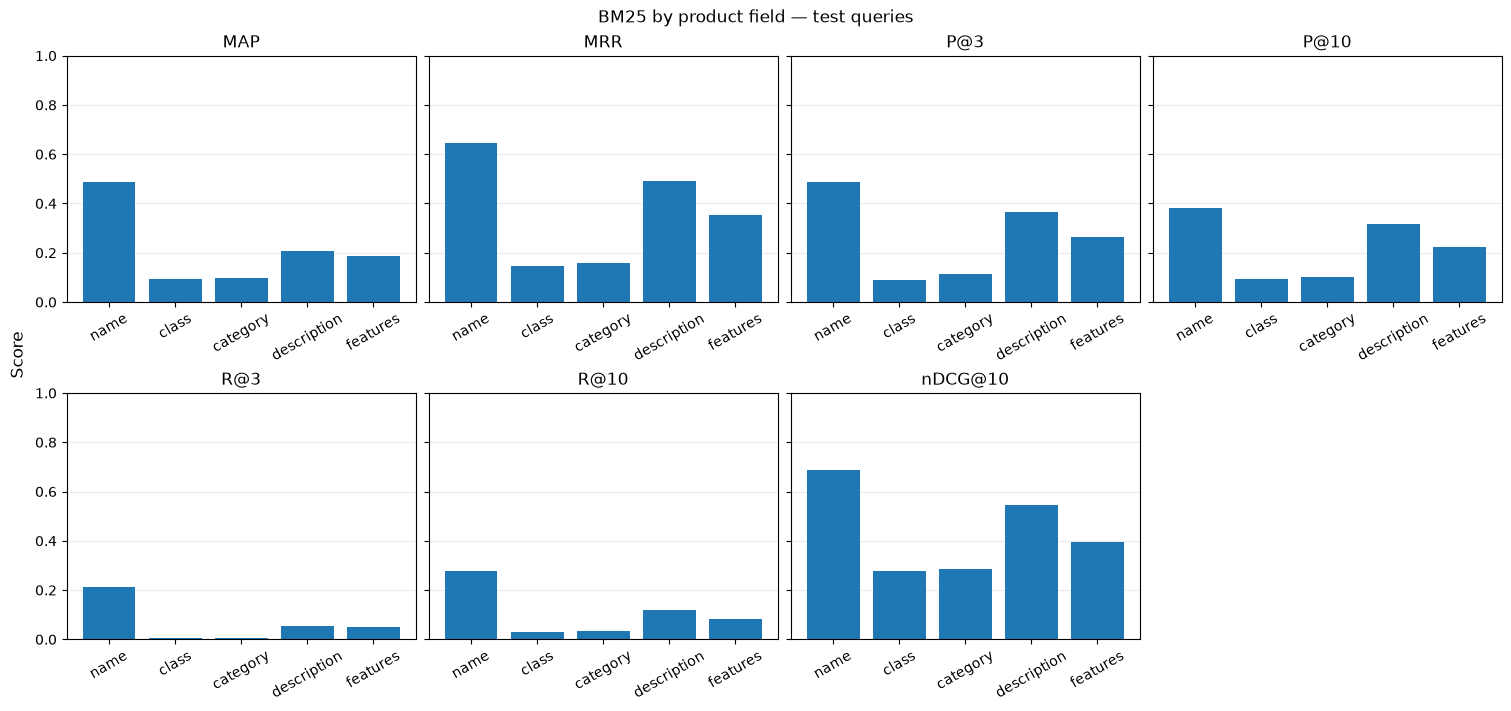

In [17]:
### YOUR CODE HERE
rows = []
for field in FIELDS:
    grid_results = grid_search(rm.bm25, grid, tune_qids, field=field)
    best = grid_results.iloc[0]
    query_eval = evaluator.evaluate(rm.bm25, test_qids, field=field, k1=best["k1"], b=best["b"])
    test_metrics = ev.summary(query_eval)
    rows.append({"field": field, **test_metrics.to_dict()})

test_results = pd.DataFrame(rows)
display(test_results)

metrics = ["MAP", "MRR", "P@3", "P@10", "R@3", "R@10", "nDCG@10"]

fig, axes = plt.subplots(
    2, 4, figsize=(15, 7), sharey=True, constrained_layout=True
)

for ax, metric in zip(axes.flat, metrics):
    ax.bar(test_results["field"], test_results[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", labelrotation=30)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

axes.flat[-1].set_visible(False)
fig.suptitle("BM25 by product field — test queries")
fig.supylabel("Score")
plt.show()

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #E0F2F1; color: #00332E; border-right: 6px solid #00897B; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>❓ سوالات مفهومی</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>کدام فیلد به‌تنهایی بهترین عملکرد را دارد؟ با توجه به ماهیت پرس‌وجوها و محتوای فیلدها توضیح دهید چرا.</li>
<li>فیلدهای <code dir="ltr">class</code> و <code dir="ltr">category</code> اطلاعات درستی درباره‌ی نوع محصول دارند، اما MAP آن‌ها بسیار پایین است. دلیل را توضیح دهید. (راهنمایی: تعداد مقادیر متفاوت این فیلدها و تعداد محصولاتی که امتیاز یکسان می‌گیرند را در نظر بگیرید.)</li>
<li>تنظیم پارامترها در کدام فیلد بیشترین بهبود را داشته است؟ چرا پارامترهای پیش‌فرض <span dir="ltr">(1.2, 0.75)</span> برای آن فیلد مناسب نیستند؟</li>
</ol>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF8E1; color: #1B2A3A; border-right: 6px solid #C9A227; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✍️ تحلیل و پاسخ</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">

</ol>
</div>

<h3 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #1F4E79; border-bottom: 2px solid #D6E2EE; padding-bottom: 6px; font-size: 18px;">بخش ۱ - دو روش استفاده از همه‌ی فیلدها: الحاق در برابر ترکیب خطی</h3>
<p dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; font-size: 15px; margin: 6px 4px 0; line-height: 1.9;">در این بخش دو روش ساده برای استفاده از همه‌ی فیلدها با BM25 مقایسه می‌شوند.</p>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📐 دو روش</b><br>
<b>(الف) الحاق:</b> همه‌ی فیلدها پشت سر هم یک سند می‌سازند و BM25 روی این سند اجرا می‌شود (<code dir="ltr">rm.bm25(..., field="all")</code>).<br>
<b>(ب) ترکیب خطی:</b> BM25 روی هر فیلد جداگانه حساب و امتیازها با وزن <span dir="ltr">w<sub>c</sub></span> جمع می‌شوند. برای سادگی، <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> بین همه‌ی فیلدها مشترک است:
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$f(q,d) = \sum_{c} w_c \cdot BM25_c(q,d)$$
</div>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF3E0; color: #4E2A00; border-right: 6px solid #EF6C00; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✏️ خواسته‌ها</b><br>
<b>(الف) الحاق</b>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>MAP روی پرس‌وجوهای تنظیم را با پارامترهای پیش‌فرض <span dir="ltr">(k<sub>1</sub> = 1.2, b = 0.75)</span> گزارش کنید.</li>
<li><span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> را روی پرس‌وجوهای تنظیم با <code dir="ltr">grid_search</code> تنظیم کنید (نتیجه‌ی آزمون در بند ۴ بخش (ب) گزارش می‌شود).</li>
<li>📊 <b>مصورسازی:</b> نتیجه‌ی جست‌وجوی شبکه‌ای را به‌صورت نقشه‌ی حرارتی (heat map) از MAP روی محورهای <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> رسم کنید.</li>
</ol>
<b>(ب) ترکیب خطی</b>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>تابع <code dir="ltr">linear_combination</code> را در فایل <code dir="ltr">retrieval_models.py</code> پیاده‌سازی کنید: BM25 هر فیلد را جداگانه (با طول و میانگین طول همان فیلد) حساب کنید و امتیازها را با وزن <span dir="ltr">w<sub>c</sub></span> جمع کنید.</li>
<li><b>تنظیم <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span>:</b> برای ساده‌سازی، به‌جای یک جفت پارامتر برای هر فیلد، یک جفت <span dir="ltr">(k<sub>1</sub>, b)</span> برای <b>همه‌ی فیلدها</b> به کار ببرید. همه‌ی وزن‌ها را ۱ بگذارید و این جفت را با <code dir="ltr">grid_search</code> پیدا کنید. توجه کنید که این پارامترها با پارامترهای بخش (الف) یکی نیستند: در (الف) اشباع و نرمال‌سازی طول یک بار روی کل محصول انجام می‌شود، اما در اینجا برای هر فیلد جداگانه. پس باید دوباره تنظیم شوند.</li>
<li><b>تنظیم وزن‌ها:</b> با ثابت ماندن <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> مرحله‌ی قبل، وزن‌ها را با <code dir="ltr">coordinate_ascent</code> تنظیم کنید. چون ضرب همه‌ی وزن‌ها در یک عدد ترتیب نتایج را تغییر نمی‌دهد، وزن <code dir="ltr">description</code> را ۱ ثابت کنید و چهار وزن دیگر را از مجموعه‌ی <span dir="ltr">{0, 0.25, 0.5, 1, 2, 3, 5}</span> انتخاب کنید.</li>
<li><b>مقایسه:</b> این چهار حالت را روی پرس‌وجوهای <b>آزمون</b> با همه‌ی معیارها در یک جدول مقایسه کنید و MAP روی پرس‌وجوهای تنظیم را هم در یک ستون کنار آن بیاورید تا فاصله‌ی تنظیم و آزمون (بیش‌برازش) دیده شود: الحاق با پارامترهای پیش‌فرض، الحاق تنظیم‌شده، ترکیب خطی با وزن‌های برابر و ترکیب خطی با وزن‌های تنظیم‌شده.</li>
<li>📊 <b>مصورسازی:</b> وزن‌های یادگرفته‌شده‌ی فیلدها و مقایسه‌ی دو روش در معیارهای مختلف را رسم کنید.</li>
</ol>
</div>

<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">(الف) الحاق همه‌ی فیلدها در یک سند</h4>

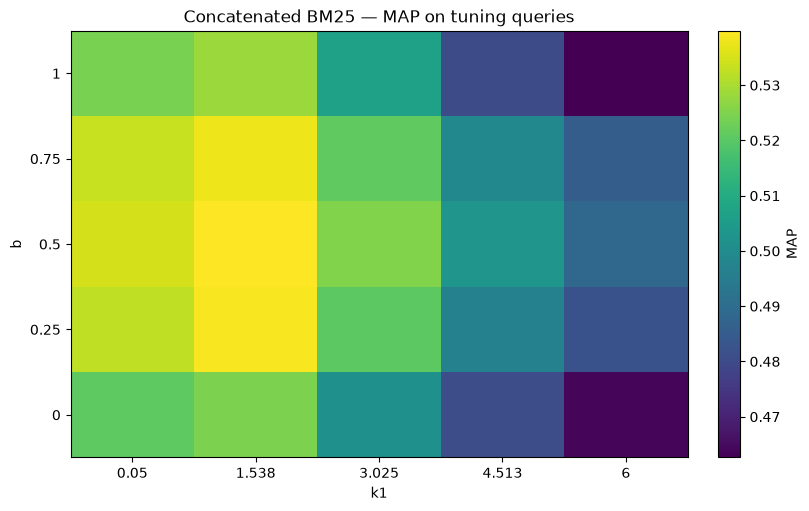

All fields MAP with default parameters: 0.5406
All fields best tuning MAP: 0.5399 (k1=1.538, b=0.5)


In [39]:
### YOUR CODE HERE

all_MAP = evaluator.mean_ap(rm.bm25, tune_qids, field="all", k1=1.2, b=0.75)

grid_results = grid_search(rm.bm25, grid, tune_qids, field="all")
best = grid_results.iloc[0]
query_eval = evaluator.evaluate(rm.bm25, test_qids, field=field, k1=best["k1"], b=best["b"])
test_metrics = ev.summary(query_eval)

heatmap = (
    grid_results.pivot(index="b", columns="k1", values="MAP")
    .sort_index()
    .sort_index(axis=1)
)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)

image = ax.imshow(
    heatmap.to_numpy(),
    origin="lower",
    aspect="auto",
    cmap="viridis",
)

ax.set_xticks(range(len(heatmap.columns)))
ax.set_xticklabels([f"{k1:.4g}" for k1 in heatmap.columns])
ax.set_yticks(range(len(heatmap.index)))
ax.set_yticklabels([f"{b:.4g}" for b in heatmap.index])

ax.set_xlabel("k1")
ax.set_ylabel("b")
ax.set_title("Concatenated BM25 — MAP on tuning queries")
fig.colorbar(image, ax=ax, label="MAP")

plt.show()

print(f"All fields MAP with default parameters: {all_MAP:.4f}")
print(f"All fields best tuning MAP: {best['MAP']:.4f} (k1={best['k1']:.4g}, b={best['b']:.4g})")

best_concat = best.copy()


<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">(ب) ترکیب خطی امتیاز BM25 فیلدها</h4>

In [40]:
### YOUR CODE HERE
# 1
weights = {field: 1.0 for field in FIELDS}

linear_grid_results = grid_search(
    rm.linear_combination,
    grid,
    tune_qids,
    weights=weights
)

best_linear = linear_grid_results.iloc[0]
linear_k1 = float(best_linear["k1"])
linear_b = float(best_linear["b"])
linear_equal_tune_map = float(best_linear["MAP"])

print(f"Best k1: {linear_k1:g}")
print(f"Best b: {linear_b:g}")
print(f"Tuning MAP: {best_linear['MAP']:.4f}")
display(linear_grid_results.head())

display(linear_grid_results.groupby("k1")["MAP"].agg(["size", "max"]))


# extend the range

coarse_results = grid_search(
    rm.linear_combination, grid, tune_qids, weights=weights
)

coarse_best = coarse_results.iloc[0]

extended_grid = extend_grid_at_edges(
    grid,
    coarse_best,
    bounds={"k1": (0.0001, None), "b": (0.0, 1.0)},
)
fine_grid = refine_grid_around_best(extended_grid, coarse_best)

print("Fine grid:")
for name, values in fine_grid.items():
    formatted = ", ".join(f"{value:.4f}" for value in values)
    print(f"  {name}: [{formatted}]")

linear_fine_results = grid_search(
    rm.linear_combination, fine_grid, tune_qids, weights=weights
)
best_linear = linear_fine_results.iloc[0]

linear_k1 = float(best_linear["k1"])
linear_b = float(best_linear["b"])
linear_equal_tune_map = float(best_linear["MAP"])

print(f"Tuning MAP: {linear_equal_tune_map:.4f}")
display(linear_fine_results.head())

# Part 3

weights_range = [0, 0.25, .5, 1, 2, 3, 5]
initial_weights = weights
fields = {
    field : weights_range for field in FIELDS if field != "description"
}

tuned_weights, linear_weighted_tune_map, weight_history = coordinate_ascent(
    lambda weights: evaluator.mean_ap(
        rm.linear_combination,
        tune_qids,
        weights=weights,
        k1=linear_k1,
        b=linear_b,
    ),
    start=initial_weights,
    candidates=fields,
    max_rounds=4,
    verbose=True
)

display(pd.Series(tuned_weights, name="Tuned weight").to_frame())
print(f"Equal-weight tuning MAP: {linear_equal_tune_map:.6f}")
print(f"Tuned-weight tuning MAP: {linear_weighted_tune_map:.6f}")


Best k1: 0.05
Best b: 0.75
Tuning MAP: 0.4834


,k1,b,MAP
0,0.05,0.75,0.4834
1,0.05,1.00,0.4832
2,0.05,0.50,0.4828
3,0.05,0.25,0.4820
4,0.05,0.00,0.4767


,size,max
k1,,
0.0500,5,0.4834
1.5375,5,0.4544
3.0250,5,0.4358
4.5125,5,0.4209
6.0000,5,0.4133


Fine grid:
  k1: [0.0001, 0.0167, 0.0334, 0.0500, 0.5458, 1.0417, 1.5375]
  b: [0.5000, 0.5833, 0.6667, 0.7500, 0.8333, 0.9167, 1.0000]
Tuning MAP: 0.4834


,k1,b,MAP
0,0.0500,0.8333,0.4834
1,0.0500,0.7500,0.4834
2,0.0500,0.5833,0.4833
3,0.0167,0.8333,0.4833
4,0.0500,0.6667,0.4833


  round 1: MAP=0.5480
  round 2: MAP=0.5480


,Tuned weight
name,5.0
class,0.5
category,1.0
description,1.0
features,1.0


Equal-weight tuning MAP: 0.483380
Tuned-weight tuning MAP: 0.548012


<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">مقایسه‌ی (الف) و (ب) روی پرس‌وجوهای آزمون</h4>

,MAP (tune),MAP (test),MRR,P@3,P@10,R@3,R@10,nDCG@10
Method,,,,,,,,
Concatenated — default,0.5406,0.5328,0.7035,0.5158,0.4358,0.2187,0.3148,0.6968
Concatenated — tuned,0.5399,0.5250,0.6902,0.5123,0.4263,0.2190,0.3136,0.6942
Linear — equal weights,0.4834,0.4805,0.6627,0.5000,0.4216,0.1880,0.2917,0.7225
Linear — tuned weights,0.5480,0.5359,0.6907,0.5386,0.4358,0.2204,0.3049,0.7376


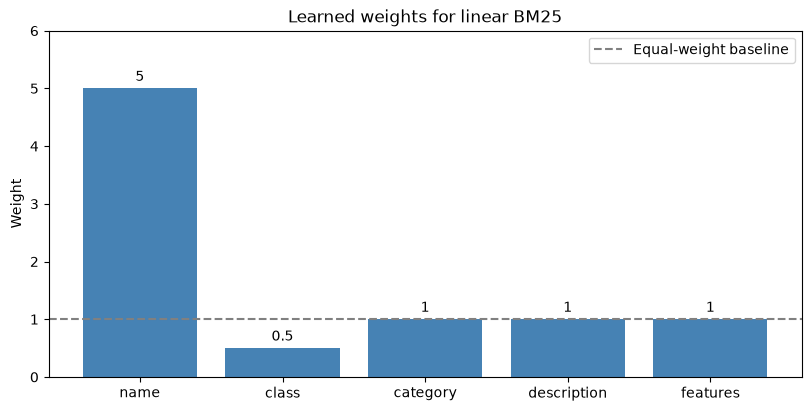

In [42]:
### YOUR CODE HERE

equal_weights = {field: 1.0 for field in FIELDS}

cases = [
    (
        "Concatenated — default",
        rm.bm25,
        {"field": "all", "k1": 1.2, "b": 0.75},
    ),
    (
        "Concatenated — tuned",
        rm.bm25,
        {
            "field": "all",
            "k1": float(best_concat["k1"]),
            "b": float(best_concat["b"]),
        },
    ),
    (
        "Linear — equal weights",
        rm.linear_combination,
        {"weights": equal_weights, "k1": linear_k1, "b": linear_b},
    ),
    (
        "Linear — tuned weights",
        rm.linear_combination,
        {"weights": tuned_weights, "k1": linear_k1, "b": linear_b},
    ),
]

rows = []

for name, score_fn, params in cases:
    tune_map = evaluator.mean_ap(score_fn, tune_qids, **params)

    test_per_query = evaluator.evaluate(score_fn, test_qids, **params)
    test_metrics = ev.summary(test_per_query).to_dict()
    test_map = test_metrics.pop("MAP")

    rows.append({
        "Method": name,
        "MAP (tune)": tune_map,
        "MAP (test)": test_map,
        **test_metrics,
    })

comparison_df = pd.DataFrame(rows).set_index("Method")
display(comparison_df.round(4))

field_weights = [tuned_weights[field] for field in FIELDS]

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
bars = ax.bar(FIELDS, field_weights, color="steelblue")

ax.axhline(1, color="gray", linestyle="--", label="Equal-weight baseline")
ax.bar_label(bars, fmt="%g", padding=3)
ax.set_ylim(0, max(1, max(field_weights)) * 1.2)
ax.set_ylabel("Weight")
ax.set_title("Learned weights for linear BM25")
ax.legend()

plt.show()

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #E0F2F1; color: #00332E; border-right: 6px solid #00897B; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>❓ سوالات مفهومی</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>روش الحاق فیلدها چه فرض ضمنی‌ای درباره‌ی اهمیت فیلدها و درباره‌ی طول سند دارد؟ با توجه به طول فیلدها (جدول بخش پیش‌پردازش) توضیح دهید چرا تطابق در فیلد <code dir="ltr">name</code> در این روش ممکن است کم‌اثر شود.</li>
<li>چرا وزن‌دهی مستقیم به امتیاز نهایی هر فیلد، راه‌حل اصولی برای ترکیب شواهد فیلدهای مختلف نیست؟ این سوال را در بخش ۳ دوباره بررسی خواهید کرد.</li>
</ol>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF8E1; color: #1B2A3A; border-right: 6px solid #C9A227; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✍️ تحلیل و پاسخ</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">

</ol>
</div>

<h3 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #1F4E79; border-bottom: 2px solid #D6E2EE; padding-bottom: 6px; font-size: 18px;">بخش ۲ - پیاده‌سازی دو اصلاح از BM25</h3>
<p dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; font-size: 15px; margin: 6px 4px 0; line-height: 1.9;">در این بخش دو اصلاح شناخته‌شده‌ی BM25 پیاده‌سازی و با BM25 مقایسه می‌شوند. هر دو روش روی سند الحاقی (همه‌ی فیلدها) اعمال و مانند BM25 تنظیم می‌شوند. هر کدام یکی از ضعف‌های BM25 را هدف گرفته است: BM25L 
برای جریمه‌ی بیش از حد اسناد بلند یک کف برای امتیاز تطابق می‌گذارد و BMX نادیده گرفتن میزان اطلاع‌رسانی واژه‌ها و میزان پوشش پرس‌وجو را هدف گرفته است.</p>

<div dir="ltr" style="text-align: left; color: #4A5A6A; font-size: 13px; margin: 4px 0;">A. Trotman, A. Puurula, B. Burgess. <i>Improvements to BM25 and Language Models Examined.</i> ADCS 2014.</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #F5EEF8; color: #1B2A3A; border-right: 6px solid #6A1B9A; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📖 مطالعه‌ی مقالات</b><br>
پیش از پیاده‌سازی، مقاله‌های زیر را مطالعه کنید. توضیحات این نوت‌بوک فقط خلاصه‌ای از فرمول‌هاست؛ انگیزه‌ی هر روش، تعریف دقیق اجزای آن و نتایج گزارش‌شده در خود مقاله‌ها آمده است.
<ul style="margin: 4px 0; padding-right: 20px;">
<li><b>BM25L</b><div dir="ltr" style="text-align: left; color: #4A5A6A; font-size: 13px; margin: 4px 0;">Y. Lv, C. Zhai. <i>When documents are very long, BM25 fails!</i> SIGIR 2011. <a href="https://dblp1.uni-trier.de/rec/conf/sigir/LvZ11.html">[dblp]</a></div></li>

<li><b>BMX:</b><div dir="ltr" style="text-align: left; color: #4A5A6A; font-size: 13px; margin: 4px 0;">X. Li, J. Lipp, A. Shakir, R. Huang, J. Li. <i>BMX: Entropy-weighted Similarity and Semantic-enhanced Lexical Search.</i> arXiv:2408.06643, 2024. <a href="https://arxiv.org/abs/2408.06643">[arXiv]</a></div></li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>۱) BM25L</b><br>
<div dir="ltr" style="text-align: left; color: #4A5A6A; font-size: 13px; margin: 4px 0;">Y. Lv, C. Zhai. <i>When documents are very long, BM25 fails!</i> SIGIR 2011. <a href="https://dblp1.uni-trier.de/rec/conf/sigir/LvZ11.html">[dblp]</a></div>
<b>مشکل:</b> در BM25، فراوانی واژه ابتدا با طول سند نرمال می‌شود:
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$c'(t,d) = \frac{c(t,d)}{1-b+b\frac{|d|}{avgdl}}$$
</div>
برای سندی که خیلی بلندتر از میانگین است، مخرج بزرگ و <span dir="ltr">c'</span> بسیار کوچک می‌شود. در نتیجه سهم واژه تقریباً صفر می‌شود؛ یعنی سند بلندی که واژه‌ی پرس‌وجو را دارد، تقریباً همان امتیاز سندی را می‌گیرد که اصلاً آن را ندارد. Lv و Zhai نشان دادند که به همین دلیل BM25 اسناد بلند را کمتر از احتمال واقعی ربطشان بازیابی می‌کند.<br>
<b>راه‌حل:</b>
BM25L به <span dir="ltr">c'</span> یک مقدار ثابت <span dir="ltr">δ</span> اضافه می‌کند و سپس اشباع را اعمال می‌کند:
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$f(q,d) = \sum_{t\in q\cap d} \log\frac{N+1}{df(t)+0.5}\cdot\frac{(k_1+1)\,\big(c'(t,d)+\delta\big)}{k_1 + c'(t,d)+\delta}$$
</div>
<ul style="margin: 4px 0; padding-right: 20px;">
<li>چون <span dir="ltr">c' ≥ 0</span>، سهم هر واژه‌ی مشترک دست‌کم <span dir="ltr">idf·(k<sub>1</sub>+1)·δ / (k<sub>1</sub>+δ)</span> است. پس هر سندی که واژه را دارد، هر قدر بلند، به‌وضوح از سندی که آن را ندارد جدا می‌شود.</li>
<li>با <span dir="ltr">δ = 0</span> فرمول همان BM25 است، با این تفاوت که نرمال‌سازی طول داخل <span dir="ltr">c'</span> انجام شده است. با افزایش <span dir="ltr">δ</span>، اثر tf و طول سند کمتر می‌شود. Lv و Zhai مقدار <span dir="ltr">δ = 0.5</span> را پیشنهاد کرده‌اند.</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>۲) BMX</b><br>
<div dir="ltr" style="text-align: left; color: #4A5A6A; font-size: 13px; margin: 4px 0;">X. Li, J. Lipp, A. Shakir, R. Huang, J. Li. <i>BMX: Entropy-weighted Similarity and Semantic-enhanced Lexical Search.</i> arXiv:2408.06643, 2024.</div>
BMX برای هر واژه‌ی پرس‌وجو یک <b>وزن آنتروپی</b> و یک <b>شباهت ساده‌ی پرس‌وجو–سند</b> اضافه می‌کند و پارامتر <span dir="ltr">b</span> ندارد:
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$f(q,d) = \sum_{i=1}^{m}\left[ idf(q_i)\cdot\frac{c(q_i,d)\,(\alpha+1)}{c(q_i,d)+\alpha\frac{|d|}{avgdl}+\alpha\,\bar{E}} + \beta\, E(q_i)\, S(q,d)\right]$$
</div>
که در آن:
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$idf(q_i) = \log\left(\frac{N - df(q_i) + 0.5}{df(q_i) + 0.5} + 1\right), \qquad S(q,d) = \frac{|q \cap d|}{m}$$
</div>
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$\tilde{E}(q_i) = -\sum_{j:\,q_i \in d_j} p_j \log p_j,\quad p_j = \text{sigmoid}\big(c(q_i, d_j)\big), \qquad E(q_i) = \frac{\tilde{E}(q_i)}{\max_k \tilde{E}(q_k)}$$
</div>
<ul style="margin: 4px 0; padding-right: 20px;">
<li>IDF روش BMX همان IDF مثبت BM25 این تمرین است.</li>
<li><span dir="ltr">m</span> تعداد واژه‌های (یکتای) پرس‌وجو و <span dir="ltr">Ē</span> میانگین <span dir="ltr">E</span> روی واژه‌های پرس‌وجو است.</li>
<li>مقادیر پیش‌فرض مقاله: <span dir="ltr">α = max(min(1.5, avgdl/100), 0.5)</span> و <span dir="ltr">β = 1 / log(1 + N)</span>.</li>
<li><b>نکته‌ی پیاده‌سازی:</b> جمله‌ی <span dir="ltr">β·E(q<sub>i</sub>)·S(q,d)</span> درون جمع روی همه‌ی واژه‌های پرس‌وجو است. پس هر سندی که دست‌کم یک واژه‌ی پرس‌وجو را داشته باشد، مقدار <span dir="ltr">β·S(q,d)·Σ<sub>i</sub> E(q<sub>i</sub>)</span> را دریافت می‌کند. گسترش پرس‌وجو مبتنی بر LLM در مقاله (WQA) لازم نیست.</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF3E0; color: #4E2A00; border-right: 6px solid #EF6C00; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✏️ خواسته‌ها</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>توابع زیر را در فایل <code dir="ltr">retrieval_models.py</code> پیاده‌سازی کنید:
<ul style="margin: 4px 0; padding-right: 20px;">
<li><code dir="ltr">bm25l</code> و <code dir="ltr">bmx</code>: دو مدل بازیابی هستند که ورودی و خروجی آن‌ها مانند <code dir="ltr">rm.bm25</code> است.</li>
<li><code dir="ltr">raw_entropy</code>: آنتروپی خام <span dir="ltr">Ẽ</span> یک واژه را از روی فهرست posting آن حساب می‌کند. <code dir="ltr">bmx</code> از آن استفاده می‌کند.</li>
<li><code dir="ltr">bmx_defaults</code>: مقادیر پیش‌فرض <span dir="ltr">α</span> و <span dir="ltr">β</span> مقاله را از روی مجموعه حساب می‌کند. <code dir="ltr">bmx</code> وقتی این دو پارامتر داده نشده باشند از آن استفاده می‌کند.</li>
</ul></li>
<li><b>BM25L:</b> <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> را با <span dir="ltr">δ = 0.5</span> (مقدار پیشنهادی Lv و Zhai) با <code dir="ltr">grid_search</code> تنظیم کنید و سپس <span dir="ltr">δ</span> را روی <span dir="ltr">{0, 0.25, 0.5, 0.75, 1, 1.5, 2}</span> جست‌وجو کنید.</li>
<li><b>BMX:</b> نتیجه را با مقادیر پیش‌فرض مقاله گزارش کنید و سپس <span dir="ltr">α</span> و <span dir="ltr">β</span> را با جست‌وجوی شبکه‌ای تنظیم کنید.</li>
<li>همه‌ی گونه‌ها را در کنار BM25 الحاقی تنظیم‌شده روی پرس‌وجوهای آزمون در یک جدول مقایسه کنید.</li>
<li>📊 <b>مصورسازی:</b> اثر <span dir="ltr">δ</span> در BM25L و اثر <span dir="ltr">α</span> و <span dir="ltr">β</span> در BMX را بر MAP رسم کنید.</li>
</ol>
</div>

In [5]:
### YOUR CODE HERE


<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">تنظیم پارامترها</h4>

In [6]:
### YOUR CODE HERE
grid_results = grid_search(rm.bm25l, grid, tune_qids, field="all")
best = grid_results.iloc[0]
k1 = float(best["k1"])
b = float(best["b"])

delta_grid = {
    "k1": k1,
    "b": b,
    "delta": [0, 0.25, .5, .75, 1, 1.5, 2]
}

grid_results_final = grid_search(rm.bm25l, delta_grid, tune_qids, field="all")
best_delta = grid_results_final.iloc[0]
best_delta = float(best_delta["delta"])
query_eval = evaluator.evaluate(rm.bm25l, test_qids, field="all", k1=best["k1"], b=best["b"], delta=best_delta)
test_metrics = ev.summary(query_eval)


In [7]:
### YOUR CODE HERE




<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">مقایسه‌ی توابع مختلف BM25 روی کوئری‌های آزمون</h4>

In [ ]:
### YOUR CODE HERE

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #E0F2F1; color: #00332E; border-right: 6px solid #00897B; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>❓ سوالات مفهومی</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>نمودار MAP بر حسب <span dir="ltr">δ</span> را برای BM25L تفسیر کنید. وقتی <span dir="ltr">δ</span> در BM25L خیلی بزرگ شود، این مدل به چه مدلی نزدیک می‌شود و چرا MAP کم می‌شود؟</li>
<li>در BMX، آنتروپی خام هر واژه از روی اسنادی که آن را دارند حساب می‌شود: <span dir="ltr">Ẽ(q<sub>i</sub>) = −Σ<sub>j</sub> p<sub>j</sub> log p<sub>j</sub></span> با <span dir="ltr">p<sub>j</sub> = sigmoid(c(q<sub>i</sub>, d<sub>j</sub>))</span>. برای پرس‌وجو «salon chair» مقدار <span dir="ltr">Ẽ</span> و <span dir="ltr">E</span> هر دو واژه را حساب کنید و به سوالات زیر پاسخ دهید:
<ul style="margin: 4px 0; padding-right: 20px;">
<li><span dir="ltr">Ẽ</span> بیشتر به کدام بستگی دارد: تعداد اسنادی که واژه را دارند (<span dir="ltr">df</span>) یا تعداد تکرار واژه در هر سند (tf)؟ چرا؟</li>
<li>رابطه‌ی <span dir="ltr">E</span> با IDF چیست؟ آیا واژه‌ای که IDF بالایی دارد، آنتروپی بالایی هم دارد؟</li>
<li>با توجه به پاسخ‌های بالا، <span dir="ltr">Ē</span> در مخرج جمله‌ی اول و <span dir="ltr">E(q<sub>i</sub>)</span> در پاداش پوشش پرس‌وجو، امتیاز را برای چه نوع پرس‌وجوها و واژه‌هایی تغییر می‌دهند؟</li>
</ul></li>
</ol>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF8E1; color: #1B2A3A; border-right: 6px solid #C9A227; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✍️ تحلیل و پاسخ</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">

</ol>
</div>

<h3 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #1F4E79; border-bottom: 2px solid #D6E2EE; padding-bottom: 6px; font-size: 18px;">بخش ۳ - BM25F</h3>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>📐 فرمول BM25F</b><br>
مطابق Pérez-Iglesias و همکاران، ابتدا فراوانی واژه در فیلدها با هم ترکیب و به یک فراوانی وزن‌دار و نرمال‌شده با طول تبدیل می‌شود و <b>اشباع (saturation) فقط یک بار و پس از ترکیب</b> اعمال می‌شود:
<div dir="ltr" style="text-align: center; margin: 8px 0;">

$$weight(t,d) = \sum_{c} \frac{occurs^{d}_{t,c}\cdot boost_c}{(1-b_c) + b_c\frac{l_c}{avl_c}}, \qquad R(q,d) = \sum_{t\in q} \frac{weight(t,d)}{k_1 + weight(t,d)}\cdot idf(t), \qquad idf(t) = \log\frac{N - df(t) + 0.5}{df(t) + 0.5}$$
</div>
<ul style="margin: 4px 0; padding-right: 20px;">
<li><span dir="ltr">l<sub>c</sub></span> طول فیلد c در سند و <span dir="ltr">avl<sub>c</sub></span> میانگین طول آن فیلد است.</li>
<li><b>IDF:</b> مطابق مقاله، IDF اصلی RSJ (<code dir="ltr">index["idf_rsj"]</code>) به کار می‌رود، نه IDF مثبت بخش‌های قبل. پس واژه‌هایی که در بیش از نیمی از محصولات آمده‌اند (جدول IDF منفی بخش ۲) وزن منفی می‌گیرند.</li>
<li><b>بدون وزن پرس‌وجو:</b> جمع روی واژه‌های <i>متمایز</i> پرس‌وجوست و <span dir="ltr">c(t,q)</span> در فرمول نیست.</li>
<li><b>بدون ضریب <span dir="ltr">(k<sub>1</sub>+1)</span>:</b> برای <span dir="ltr">k<sub>1</sub></span> ثابت این ضریب ترتیب رتبه‌بندی را تغییر نمی‌دهد و در مقاله نیامده است.</li>
<li>تفاوت اصلی با ترکیب خطی در محل اشباع است: در <code dir="ltr">linear_combination</code> اشباع <b>درون</b> حلقه‌ی روی فیلدها (یک بار برای هر فیلد) رخ می‌دهد، اما در BM25F <b>پس از</b> آن (فقط یک بار).</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF3E0; color: #4E2A00; border-right: 6px solid #EF6C00; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✏️ خواسته‌ها</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>تابع <code dir="ltr">bm25f</code> را در فایل <code dir="ltr">retrieval_models.py</code> پیاده‌سازی کنید. ورودی‌های آن <span dir="ltr">k<sub>1</sub></span>، دیکشنری <code dir="ltr">boost</code> و دیکشنری <code dir="ltr">b</code> (یک مقدار برای هر فیلد) است. فرمول را دقیقاً مطابق مقاله پیاده کنید: IDF اصلی RSJ (<code dir="ltr">index["idf_rsj"]</code>) و هر واژه‌ی متمایز پرس‌وجو یک بار.</li>
<li><b>گام ۱:</b> BM25F را دقیقاً با وزن‌ها، <span dir="ltr">k<sub>1</sub></span> و <span dir="ltr">b</span> ترکیب خطی تنظیم‌شده (بخش ۱) اجرا کنید و با ترکیب خطی و با BM25F پیش‌فرض (<span dir="ltr">boost = 1, k<sub>1</sub> = 1.2, b = 0.75</span>) مقایسه کنید.</li>
<li><b>گام ۲:</b> BM25F یازده پارامتر دارد: <span dir="ltr">k<sub>1</sub></span>، پنج <span dir="ltr">boost<sub>c</sub></span> و پنج <span dir="ltr">b<sub>c</sub></span>. <code dir="ltr">boost_description</code> را برابر ۱ ثابت کنید و ۱۰ پارامتر دیگر را با <code dir="ltr">coordinate_ascent</code> و با شروع از پارامترهای گام ۱ تنظیم کنید.</li>
<li>📊 <b>مصورسازی:</b> روند بهبود MAP در طول coordinate ascent را در کنار خط مبنای BM25 الحاقی و ترکیب خطی رسم کنید. همچنین حساسیت MAP به هر <span dir="ltr">boost<sub>c</sub></span> و <span dir="ltr">b<sub>c</sub></span> را نشان دهید: هر پارامتر به‌تنهایی تغییر کند و بقیه در مقدار تنظیم‌شده ثابت بمانند.</li>
</ol>
</div>

<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">گام ۱ · BM25F با پارامترهای ترکیب خطی</h4>

In [10]:
### YOUR CODE HERE

<h4 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #1F4E79; font-size: 16px; margin-top: 18px;">گام ۲ · تنظیم BM25F</h4>

In [1]:
### YOUR CODE HERE

In [2]:
### YOUR CODE HERE

<h3 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #1F4E79; border-bottom: 2px solid #D6E2EE; padding-bottom: 6px; font-size: 18px;">جمع‌بندی - همه‌ی روش‌ها روی پرس‌وجوهای آزمون</h3>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF3E0; color: #4E2A00; border-right: 6px solid #EF6C00; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✏️ خواسته‌ها</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>همه‌ی روش‌ها را با پارامترهایی که روی پرس‌وجوهای تنظیم انتخاب شده‌اند، روی پرس‌وجوهای آزمون ارزیابی و در یک جدول گزارش کنید.</li>
<li>MAP روی پرس‌وجوهای تنظیم و آزمون را برای هر روش کنار هم قرار دهید تا میزان بیش‌برازش (over-fitting) دیده شود.</li>
<li><b>آزمون معناداری:</b> تابع <code dir="ltr">significance_test</code> را در فایل <code dir="ltr">evaluation.py</code> پیاده‌سازی کنید. این تابع هر روش را با یک روش پایه با <b>آزمون t زوجی (paired t-test)</b> روی مقادیر هر پرس‌وجو مقایسه می‌کند.
<ul style="margin: 4px 0; padding-right: 20px;">
<li><b>ورودی:</b> <code dir="ltr">runs</code> دیکشنری‌ای از نام روش به خروجی <code dir="ltr">evaluate</code> روی پرس‌وجوهای آزمون (یک سطر برای هر پرس‌وجو و یک ستون برای هر معیار)؛ <code dir="ltr">baseline</code> نام روش پایه؛ <code dir="ltr">metrics</code> معیارهایی که مقایسه می‌شوند؛ <code dir="ltr">alpha</code> سطح معناداری.</li>
<li><b>خروجی:</b> یک DataFrame با یک سطر برای هر روش (به‌جز روش پایه) و هر معیار، شامل میانگین روش، میانگین روش پایه، اختلاف میانگین‌ها، <i>better</i> و <i>worse</i> (تعداد پرس‌وجوهایی که روش در آن‌ها از روش پایه بهتر یا بدتر است)، <span dir="ltr">p-value</span> و اینکه تفاوت معنادار است یا نه (<span dir="ltr">p-value &lt; alpha</span>).</li>
</ul>
سپس همه‌ی روش‌ها را با <b>BM25 concat</b> با پارامترهای بهینه‌اش (خط پایه) روی AP و nDCG@10 مقایسه کنید. برای آزمون t زوجی می‌توانید از <code dir="ltr">scipy.stats.ttest_rel</code> استفاده کنید.</li>
<li>📊 <b>مصورسازی:</b> نتایج آزمون همه‌ی روش‌ها را در یک نمودار مقایسه کنید و فاصله‌ی MAP تنظیم و آزمون را هم نشان دهید.</li>
</ol>
</div>

In [3]:
### YOUR CODE HERE

In [4]:
### YOUR CODE HERE

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #E0F2F1; color: #00332E; border-right: 6px solid #00897B; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>❓ سوالات مفهومی</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">
<li>کدام روش‌ها به‌طور معنادار از BM25
 الحاقی تنظیم‌شده بهتر هستند؟</li>
<li>اگر قرار بود یکی از این روش‌ها را در یک موتور جست‌وجوی فروشگاهی واقعی به کار ببرید، کدام را انتخاب می‌کردید؟ مزایا و هزینه‌های انتخابتان را بیان کنید.</li>
</ol>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FFF8E1; color: #1B2A3A; border-right: 6px solid #C9A227; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px;">
<b>✍️ تحلیل و پاسخ</b><br>
<ol style="margin: 4px 0; padding-right: 20px;">

</ol>
</div>

<h2 dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; color: #FFFFFF; background: #1F4E79; border-radius: 10px; padding: 12px 20px; margin-top: 28px; font-size: 22px;">📌 · نکات مهم</h2>
<p dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; color: #4A5A6A; font-size: 15px; margin: 6px 4px 0;">این بخش را پیش از شروع و پیش از ارسال تمرین مطالعه کنید.</p>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px; ">
<b>📅 مهلت و نحوه‌ی ارسال</b>
<ul style="margin: 4px 0; padding-right: 20px;">
<li><b>مهلت تحویل:</b> ۲۶ آبان ۱۴۰۵</li>
<li><b>حداکثر مهلت ارسال با تأخیر:</b> ۳ آذر ۱۴۰۵</li>
<li>نوت‌بوک را با نام <code dir="ltr">IIR_CA#_code_StudentID.ipynb</code> ذخیره کنید و همراه گزارش، در یک فایل فشرده با نام <code dir="ltr">IIR_CA#_StudentID</code> در سامانه Elearn بارگذاری کنید (مثلاً <code dir="ltr">IIR_CA1_810100000</code>).</li>
<li>اگر هنگام بارگذاری، سامانه Elearn در دسترس نبود یا کند بود، تمرین را برای Head TA درس ایمیل کنید.</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px; ">
<b>🧭 نحوه‌ی انجام تمرین</b>
<ul style="margin: 4px 0; padding-right: 20px;">
<li>کد و تحلیل هر بخش را در همان بخش این نوت‌بوک بنویسید و ساختار سلول‌ها را حفظ کنید تا نوت‌بوک خوانا بماند.</li>
<li>همه‌ی سلول‌ها باید پیش از ارسال اجرا شده باشند و خروجی آن‌ها در فایل دیده شود. به کدی که خروجی آن در فایل نیست نمره‌ای تعلق نمی‌گیرد.</li>
<li>کدها باید دوباره قابل اجرا باشند. اگر به تنظیمات خاصی نیاز دارند، آن را در همین نوت‌بوک توضیح دهید.</li>
<li>برای آشنایی بیشتر با Markdown می‌توانید از <a href="https://github.com/tajaddini/Persian-Markdown/blob/master/learn-MD.md">این راهنما</a> استفاده کنید.</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #EAF1F8; color: #1B2A3A; border-right: 6px solid #1F4E79; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px; ">
<b>⏱ تأخیر و تحویل شفاهی</b>
<ul style="margin: 4px 0; padding-right: 20px;">
<li>برای همه‌ی تمرین‌ها در مجموع ۱۴ روز تأخیر بدون جریمه دارید. پس از آن، به ازای هر روز تأخیر ۱۰ درصد از نمره‌ی تمرین کسر می‌شود.</li>
<li>هر تمرین حداکثر ۷ روز با تأخیر پذیرفته می‌شود.</li>
<li>تا دو هفته‌ی کاری پس از مهلت تحویل، ممکن است دستیار طراح تمرین از برخی دانشجویان تحویل شفاهی بخواهد.</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #FDECEA; color: #5A1010; border-right: 6px solid #C62828; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px; ">
<b>🛡 صداقت علمی</b>
<ul style="margin: 4px 0; padding-right: 20px;">
<li>تمرین باید به‌صورت تک‌نفره انجام شود. هرگونه کپی به معنای نمره‌ی صفر برای همه‌ی طرف‌هاست. کمک گرفتن از دیگران فقط در حد یادگیری مطلب مجاز است و نباید به مشابهت در پاسخ‌ها منجر شود.</li>
<li>نوت‌بوک تعدادی از دانشجویان به‌صورت تصادفی بررسی می‌شود تا مطمئن شویم کد شما واقعاً همان خروجی‌های موجود در فایل را تولید می‌کند. ارسال پاسخ بدون کدی که آن را تولید کند، تخلف جدی محسوب می‌شود.</li>
<li>شباهت کدها به‌طور خودکار نیز بررسی می‌شود.</li>
</ul>
</div>

<div dir="rtl" style="font-family: Vazirmatn, Vazir, Tahoma, sans-serif; box-sizing: border-box; width: 100%; max-width: 100%; background: #F5EEF8; color: #1B2A3A; border-right: 6px solid #6A1B9A; border-radius: 10px; padding: 14px 20px; line-height: 1.9; font-size: 15px; ">
<b>🤖 استفاده‌ی مسئولانه از هوش مصنوعی</b><br>
پیش از استفاده از ابزارهای هوش مصنوعی، بخش «استفاده‌ی مسئولانه از هوش مصنوعی» در فایل صورت تمرین را مطالعه کنید. در صورت تخطی از این چارچوب، نمره‌ی آن تمرین صفر در نظر گرفته می‌شود. اظهارنامه‌ی زیر را در پایان گزارش و این نوت‌بوک نگه دارید:
<div style="box-sizing: border-box; width: 100%; max-width: 100%; background: #FFFFFF; color: #1B2A3A; border: 1px solid #D6E2EE; border-radius: 8px; padding: 10px 14px; margin-top: 10px;">«تأیید می‌کنم که از LLM‌ها مطابق با دستورالعمل‌های بارگذاری شده در سامانه Elearn درس به طور مسئولانه استفاده کرده‌ام. تمام اجزای کار خود را درک می‌کنم و آماده بحث شفاهی درباره آنها هستم.»</div>
</div>